# Lab 3 - Keypoints

Stefan-Teodor Iancu (ianstef). Part 1: keypoints of one image with several detectors, their 8x8
distribution and their robustness to blur, rotation and Gaussian noise. Part 2: classify the test
photos of three places in Iasi (BCU, BVD_COPOU, UAIC) by matching keypoints against every train photo.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import random
import time
from collections import Counter
from IPython.display import Markdown, display

%matplotlib inline
print('OpenCV', cv2.__version__)

OpenCV 5.0.0


### Helpers: detectors and matchers

Every detector returns `(keypoints, descriptors, norm)`. `norm` is `cv2.NORM_L2` for float descriptors
(SIFT, KAZE, Harris+SIFT) and `cv2.NORM_HAMMING` for binary ones (ORB, BRISK, AKAZE, FAST+BRISK).
All detectors work on the grayscale image.

In [2]:
# OpenCV 5 moved BRISK / AKAZE / KAZE / SURF into cv2.xfeatures2d: look in cv2 first, then there
def cv_create(name, **kwargs):
    for module in (cv2, getattr(cv2, 'xfeatures2d', None)):
        if module is not None and hasattr(module, name + '_create'):
            return getattr(module, name + '_create')(**kwargs)
    raise RuntimeError(f'{name} is not available in this OpenCV build')


# SURF is patented; most pip wheels are built without it
def surf_available():
    try:
        cv_create('SURF', hessianThreshold=400)
        return True
    except (cv2.error, RuntimeError):
        return False


def to_gray(img):
    if img.ndim == 3:
        return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img


# Harris corners as cv2.KeyPoint: response > 0.01 * max, 3x3 non-maximum suppression (one corner = one point)
def harris_keypoints(gray, block_size=2, ksize=3, k=0.04, rel_threshold=0.01, kp_size=7):
    response = cv2.cornerHarris(np.float32(gray), block_size, ksize, k)
    threshold = rel_threshold * response.max()
    local_max = cv2.dilate(response, np.ones((3, 3), np.uint8))
    mask = (response > threshold) & (response == local_max)
    ys, xs = np.nonzero(mask)
    return [cv2.KeyPoint(float(x), float(y), kp_size, -1, float(response[y, x]))
            for x, y in zip(xs, ys)]


# Harris has no descriptor: SIFT.compute on the corners (no orientation -> upright patch)
def detect_harris(gray):
    kps = harris_keypoints(gray)
    if not kps:
        return [], None, cv2.NORM_L2
    kps, desc = cv2.SIFT_create().compute(gray, kps)
    return list(kps), desc, cv2.NORM_L2


# FAST has no descriptor: BRISK.compute on the corners (BRISK estimates an orientation)
def detect_fast(gray, threshold=20):
    kps = cv2.FastFeatureDetector_create(threshold=threshold).detect(gray, None)
    if not kps:
        return [], None, cv2.NORM_HAMMING
    kps, desc = cv_create('BRISK').compute(gray, kps)
    return list(kps), desc, cv2.NORM_HAMMING


def make_detect_and_compute(create_fn, norm):
    def detect(gray):
        kps, desc = create_fn().detectAndCompute(gray, None)
        return list(kps), desc, norm
    return detect


# Part 1 methods: name -> function(gray) -> (keypoints, descriptors, norm)
def part1_methods(orb_features=1000):
    methods = {
        'Harris': detect_harris,
        'FAST': detect_fast,
        'SIFT': make_detect_and_compute(lambda: cv2.SIFT_create(), cv2.NORM_L2),
        'ORB': make_detect_and_compute(lambda: cv2.ORB_create(nfeatures=orb_features), cv2.NORM_HAMMING),
        'BRISK': make_detect_and_compute(lambda: cv_create('BRISK'), cv2.NORM_HAMMING),
        'AKAZE': make_detect_and_compute(lambda: cv_create('AKAZE'), cv2.NORM_HAMMING),
        'KAZE': make_detect_and_compute(lambda: cv_create('KAZE'), cv2.NORM_L2),
    }
    if surf_available():
        methods['SURF'] = make_detect_and_compute(
            lambda: cv_create('SURF', hessianThreshold=400), cv2.NORM_L2)
    return methods


# keep the max_kp keypoints with the highest response (used to cap BRISK in Part 2)
def keep_strongest(kps, desc, max_kp):
    if max_kp is None or len(kps) <= max_kp:
        return kps, desc
    order = np.argsort([-kp.response for kp in kps])[:max_kp]
    return [kps[i] for i in order], desc[order]


# Part 2 methods: list of (factory, norm, max_kp) from normal to more and more relaxed parameters
def part2_method_variants():
    return {
        'SIFT': [
            (lambda ct=ct: cv2.SIFT_create(nfeatures=500, contrastThreshold=ct), cv2.NORM_L2, None)
            for ct in (0.04, 0.01, 0.001)
        ],
        'ORB': [
            (lambda ft=ft: cv2.ORB_create(nfeatures=500, fastThreshold=ft), cv2.NORM_HAMMING, None)
            for ft in (20, 5, 1)
        ],
        'AKAZE': [
            (lambda th=th: cv_create('AKAZE', threshold=th), cv2.NORM_HAMMING, None)
            for th in (0.001, 0.0001, 0.00001)
        ],
        'BRISK': [
            (lambda th=th: cv_create('BRISK', thresh=th), cv2.NORM_HAMMING, 1000)
            for th in (30, 10, 1)
        ],
        'KAZE': [
            (lambda th=th: cv_create('KAZE', threshold=th), cv2.NORM_L2, None)
            for th in (0.001, 0.0001, 0.00001)
        ],
    }

In [3]:
# brute force with cross check (a match must be the best in both directions)
def bf_matches(desc1, desc2, norm):
    if desc1 is None or desc2 is None or len(desc1) == 0 or len(desc2) == 0:
        return []
    matcher = cv2.BFMatcher(norm, crossCheck=True)
    return sorted(matcher.match(desc1, desc2), key=lambda m: m.distance)


# kNN (k=2) brute force + Lowe ratio test
def knn_matches(desc1, desc2, norm, ratio=0.75):
    if desc1 is None or desc2 is None or len(desc1) == 0 or len(desc2) < 2:
        return []
    matcher = cv2.BFMatcher(norm)
    pairs = matcher.knnMatch(desc1, desc2, k=2)
    good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    return sorted(good, key=lambda m: m.distance)


# FLANN (kd-tree) kNN + ratio test, only for float descriptors
def flann_knn_matches(desc1, desc2, ratio=0.75):
    if desc1 is None or desc2 is None or len(desc1) == 0 or len(desc2) < 2:
        return []
    index_params = dict(algorithm=1, trees=5)  # FLANN_INDEX_KDTREE
    search_params = dict(checks=50)
    matcher = cv2.FlannBasedMatcher(index_params, search_params)
    pairs = matcher.knnMatch(np.float32(desc1), np.float32(desc2), k=2)
    good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    return sorted(good, key=lambda m: m.distance)


# a match is correct when keypoint 1, moved with the known 2x3 transform, lands within tol px of keypoint 2
# (for blur and noise the transform is the identity)
def count_correct(matches, kps1, kps2, affine, tol=5.0):
    if not matches:
        return 0
    p1 = np.array([kps1[m.queryIdx].pt for m in matches], dtype=np.float64)
    p2 = np.array([kps2[m.trainIdx].pt for m in matches], dtype=np.float64)
    p1h = np.hstack([p1, np.ones((len(p1), 1))])
    moved = p1h @ affine.T
    dist = np.linalg.norm(moved - p2, axis=1)
    return int((dist <= tol).sum())


# small markdown table
def show_table(header, rows):
    lines = ['| ' + ' | '.join(str(h) for h in header) + ' |', '|' + '---|' * len(header)]
    for r in rows:
        lines.append('| ' + ' | '.join(str(v) for v in r) + ' |')
    display(Markdown('\n'.join(lines)))

In [4]:
print('SURF available:', surf_available())

SURF available: False


SURF is **not available**: the installed OpenCV wheel is built without the non-free module
(`SURF_create` raises "This algorithm is patented and is excluded"). `part1_methods()` checks for it and
would add it automatically if it existed. Seven methods are used: Harris, FAST, SIFT, ORB, BRISK, AKAZE, KAZE.

---

### Part 1. **Keypoints of one image**

Main image: `data/train/BCU/BCU_00001.JPG` (516x387, the BCU library with a statue, windows, cars and sky).

In [5]:
GRID = 8
RATIO = 0.75
DRAW_BEST = 50


# run every method on a gray image -> {name: (kps, desc, norm, seconds)}
def detect_all(gray, methods):
    out = {}
    for name, fn in methods.items():
        t = time.time()
        kps, desc, norm = fn(gray)
        out[name] = (kps, desc, norm, time.time() - t)
    return out


def norm_name(norm):
    return 'L2' if norm == cv2.NORM_L2 else 'HAMMING'


# count keypoints in n x n non-overlapping regions of the image
def grid_counts(kps, shape, n=GRID):
    h, w = shape[:2]
    counts = np.zeros((n, n), dtype=int)
    for kp in kps:
        x, y = kp.pt
        col = min(int(x * n / w), n - 1)
        row = min(int(y * n / h), n - 1)
        counts[row, col] += 1
    return counts


def show_keypoints(img, results, title):
    names = list(results)
    nrows = int(np.ceil((len(names) + 1) / 4))
    fig, axs = plt.subplots(nrows, 4, figsize=(18, 3.8 * nrows))
    axs = axs.ravel()
    axs[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axs[0].set_title('Original image')
    for ax, name in zip(axs[1:], names):
        kps = results[name][0]
        # small plain markers (the rich circles of ORB/BRISK hide the image)
        drawn = cv2.drawKeypoints(img, kps, None, color=(0, 255, 0))
        ax.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
        ax.set_title(f'{name}: {len(kps)} keypoints')
    for ax in axs:
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


COUNT_HEADER = ['method', 'keypoints', 'desc length', 'desc dtype', 'norm', 'empty cells (of 64)',
                'max cell', 'max cell share', 'mean kp size', 'detect ms']


# keypoint counts table + 8x8 grids
def count_rows(img, results):
    rows, grids = [], {}
    for name, (kps, desc, norm, seconds) in results.items():
        counts = grid_counts(kps, img.shape)
        grids[name] = counts
        n = len(kps)
        rows.append([
            name, n,
            desc.shape[1] if desc is not None else 0,
            str(desc.dtype) if desc is not None else '-',
            norm_name(norm),
            int((counts == 0).sum()),
            int(counts.max()),
            round(counts.max() / n, 3) if n else 0,
            round(float(np.mean([kp.size for kp in kps])), 2) if n else 0,
            round(seconds * 1000, 1),
        ])
    return rows, grids


def show_grids(grids, title):
    names = list(grids)
    nrows = int(np.ceil(len(names) / 4))
    fig, axs = plt.subplots(nrows, 4, figsize=(18, 4.2 * nrows))
    axs = axs.ravel()
    for ax in axs:
        ax.axis('off')
    for ax, name in zip(axs, names):
        counts = grids[name]
        ax.imshow(counts, cmap='viridis')
        for r in range(counts.shape[0]):
            for c in range(counts.shape[1]):
                v = counts[r, c]
                ax.text(c, r, str(v), ha='center', va='center', fontsize=7,
                        color='white' if v < counts.max() * 0.6 else 'black')
        ax.set_title(f'{name} ({counts.sum()} kp)')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [6]:
img = cv2.imread('data/train/BCU/BCU_00001.JPG', cv2.IMREAD_COLOR)
gray = to_gray(img)
methods = part1_methods()
print(f'image {img.shape[1]}x{img.shape[0]}, methods: {", ".join(methods)}')

base = detect_all(gray, methods)

image 516x387, methods: Harris, FAST, SIFT, ORB, BRISK, AKAZE, KAZE


### 1a. **Keypoints drawn on the image**

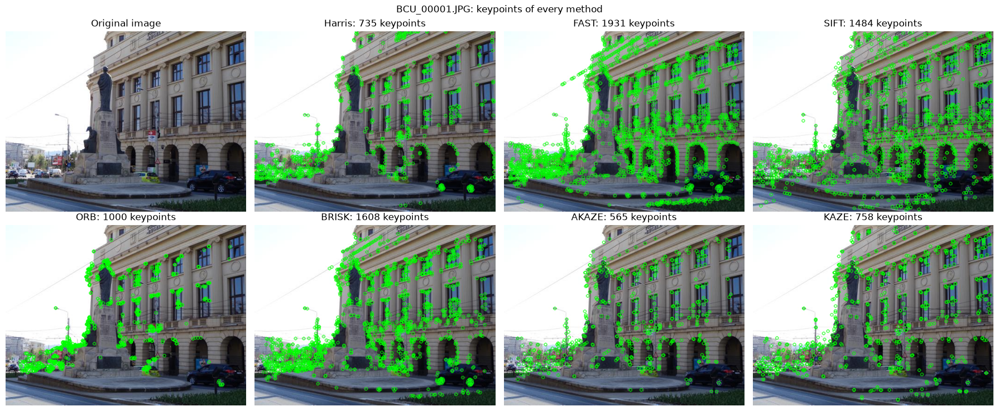

In [7]:
show_keypoints(img, base, 'BCU_00001.JPG: keypoints of every method')

Corner detectors (Harris, FAST, ORB, BRISK) cluster on high-contrast corners and textures (trees, cars,
window frames). Blob / scale-space detectors (SIFT, KAZE, AKAZE) spread more evenly over all structured
regions. Nobody puts points in the sky or on flat walls.

---

### 1b. **Number of keypoints and 8x8 spatial distribution**

| method | keypoints | desc length | desc dtype | norm | empty cells (of 64) | max cell | max cell share | mean kp size | detect ms |
|---|---|---|---|---|---|---|---|---|---|
| Harris | 735 | 128 | float32 | L2 | 14 | 92 | 0.125 | 7.0 | 5.1 |
| FAST | 1931 | 64 | uint8 | HAMMING | 7 | 106 | 0.055 | 7.0 | 10.4 |
| SIFT | 1484 | 128 | float32 | L2 | 9 | 62 | 0.042 | 4.12 | 14.9 |
| ORB | 1000 | 32 | uint8 | HAMMING | 25 | 120 | 0.12 | 53.83 | 53.3 |
| BRISK | 1608 | 64 | uint8 | HAMMING | 11 | 113 | 0.07 | 18.59 | 16.0 |
| AKAZE | 565 | 61 | uint8 | HAMMING | 16 | 32 | 0.057 | 6.72 | 7.7 |
| KAZE | 758 | 64 | float32 | L2 | 13 | 52 | 0.069 | 6.68 | 27.3 |

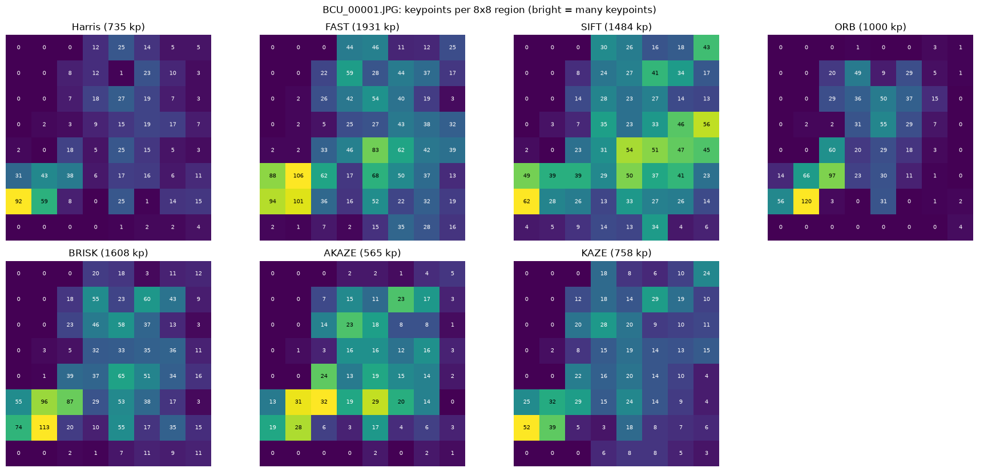

In [8]:
counts, grids = count_rows(img, base)
show_table(COUNT_HEADER, counts)
show_grids(grids, 'BCU_00001.JPG: keypoints per 8x8 region (bright = many keypoints)')

Harris 735, FAST 1931, SIFT 1484, ORB 1000 (cap `nfeatures=1000`), BRISK 1608, AKAZE 565, KAZE 758 keypoints.
The sky (rows 0-4, columns 0-1) is empty for every method. FAST is the most spread (7 empty cells, max share 5.5 %),
SIFT the most uniform real detector (62 points in the fullest cell, 4.2 %), ORB the most clustered
(25 empty cells, 120 points in one cell = the busy street on the left). AKAZE / KAZE find fewer points
but well spread. Timings vary by a few ms between runs (ORB includes the first-call initialisation).

---

### Helpers for 1c-1e: transformations, matching, plots

For every transformed image we detect again and match original vs transformed with brute force + cross check
(BF), kNN + ratio 0.75 (kNN) and, for float descriptors, FLANN + ratio 0.75. Because the transformation is
known, a match is **correct** when the moved original keypoint lands within 5 px of the matched one.
On the kNN matches we also run `cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)` as in the lab notebook
(only with at least 10 matches) and count the inliers; the image corners moved with the homography are drawn
as a green frame on the transformed image.

In [9]:
def identity_affine():
    return np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]])


# (label, numeric param, group, function(img) -> img, affine)
def blur_transforms():
    out = []
    for k in (3, 5, 9, 15):
        out.append((f'mean_k{k}', k, 'mean', lambda im, k=k: cv2.blur(im, (k, k)), identity_affine()))
    for k in (3, 5, 9, 15):
        out.append((f'gauss_k{k}', k, 'gauss',
                    lambda im, k=k: cv2.GaussianBlur(im, (k, k), 0), identity_affine()))
    for s in (1, 3, 5):
        out.append((f'gauss_k15_sigma{s}', s, 'gauss_sigma',
                    lambda im, s=s: cv2.GaussianBlur(im, (15, 15), s), identity_affine()))
    return out


def rotation_transforms(shape):
    h, w = shape[:2]
    center = ((w - 1) / 2.0, (h - 1) / 2.0)
    out = []
    for angle in (15, 30, 45, 90, 135, 180):
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        out.append((f'rot{angle}', angle, 'rotation',
                    lambda im, M=M: cv2.warpAffine(im, M, (w, h)), M))
    return out


# Gaussian noise added in float, clipped to 0..255, fixed seed
def add_gaussian_noise(image, sigma, mean=0, seed=0):
    rng = np.random.default_rng(seed)
    noisy_image = image + rng.normal(mean, sigma, image.shape)
    return np.clip(noisy_image, 0, 255).astype(np.uint8)


def noise_transforms():
    return [(f'noise_sigma{s}', s, 'noise', lambda im, s=s: add_gaussian_noise(im, s), identity_affine())
            for s in (5, 10, 20, 30, 50)]


MIN_MATCH_COUNT = 10


# RANSAC homography between the matched points -> (matrix or None, number of inliers)
def homography_inliers(matches, kps1, kps2):
    if len(matches) < MIN_MATCH_COUNT:
        return None, 0
    src_pts = np.float32([kps1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kps2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
    M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    if M is None:
        return None, 0
    return M, int(mask.sum())


# corners of the original image moved with the homography, drawn on the transformed image
def draw_found_frame(img, timg, M):
    h, w = img.shape[:2]
    pts = np.float32([[0, 0], [0, h], [w, h], [w, 0]]).reshape(-1, 1, 2)
    dst = cv2.perspectiveTransform(pts, M)
    return cv2.polylines(timg.copy(), [np.int32(dst)], True, (0, 255, 0), 6, cv2.LINE_AA)


# rows: [transform, param, group, method, kp_original, kp_transformed, bf_matches, bf_correct,
#        knn_matches, knn_correct, flann_matches, flann_correct, ransac_inliers]
# drawn: {label: matches image of draw_method} for the labels in draw_labels
def robustness(img, base, methods, transforms, draw_labels, draw_method='SIFT'):
    rows, drawn = [], {}
    for label, param, group, fn, affine in transforms:
        timg = fn(img)
        tgray = to_gray(timg)
        tres = detect_all(tgray, methods)
        for name in methods:
            kps1, desc1, norm, _ = base[name]
            kps2, desc2, _, _ = tres[name]
            bf = bf_matches(desc1, desc2, norm)
            knn = knn_matches(desc1, desc2, norm, RATIO)
            if norm == cv2.NORM_L2:
                fl = flann_knn_matches(desc1, desc2, RATIO)
                flann_n, flann_ok = len(fl), count_correct(fl, kps1, kps2, affine)
            else:
                flann_n, flann_ok = '', ''
            M, inliers = homography_inliers(knn, kps1, kps2)
            rows.append([label, param, group, name, len(kps1), len(kps2),
                         len(bf), count_correct(bf, kps1, kps2, affine),
                         len(knn), count_correct(knn, kps1, kps2, affine),
                         flann_n, flann_ok, inliers])
            if label in draw_labels and name == draw_method:
                scene = draw_found_frame(img, timg, M) if M is not None else timg
                drawn[label] = cv2.drawMatches(img, kps1, scene, kps2, bf[:DRAW_BEST], None,
                                               matchColor=(0, 255, 0),
                                               flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    return rows, drawn

In [10]:
def method_colors(sel):
    names = list(dict.fromkeys(r[3] for r in sel))
    return {m: f'C{i}' for i, m in enumerate(names)}


def show_drawn(drawn, title):
    fig, axs = plt.subplots(len(drawn), 1, figsize=(13, 4.9 * len(drawn)))
    axs = np.atleast_1d(axs)
    for ax, (label, im) in zip(axs, drawn.items()):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(f'{label}: original (left) vs transformed (right), 50 best BF matches')
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# two pivot tables per group: kp / BF (correct) / kNN (correct) and FLANN (correct) / RANSAC inliers
def show_group_tables(rows, group, prefix, caption):
    sel = [r for r in rows if r[2] == group]
    params = sorted({r[1] for r in sel})
    cell = {(r[3], r[1]): r for r in sel}
    t1, t2 = [], []
    for m in method_colors(sel):
        line1 = [f'{m} ({cell[(m, params[0])][4]})']
        line2 = [m]
        for p in params:
            r = cell[(m, p)]
            line1.append(f'{r[5]} / {r[6]} ({r[7]}) / {r[8]} ({r[9]})')
            line2.append((f'{r[10]} ({r[11]})' if r[10] != '' else '-') + f' / {r[12]}')
        t1.append(line1)
        t2.append(line2)
    display(Markdown(f'**{caption}** - kp transformed / BF (correct) / kNN (correct)'))
    show_table(['method (orig kp)'] + [f'{prefix}{p}' for p in params], t1)
    display(Markdown(f'**{caption}** - FLANN (correct) / RANSAC inliers'))
    show_table(['method'] + [f'{prefix}{p}' for p in params], t2)


# 2x3: rows = all matches / geometrically correct; columns = BF / kNN / FLANN
def plot_matches(rows, group, xlabel, title):
    sel = [r for r in rows if r[2] == group]
    colors = method_colors(sel)
    fig, axs = plt.subplots(2, 3, figsize=(16, 8))
    panels = [(0, 0, 6, 'Brute force (crossCheck): all matches'),
              (0, 1, 8, 'kNN k=2 + ratio 0.75: all matches'),
              (0, 2, 10, 'FLANN + ratio 0.75 (float desc.): all matches'),
              (1, 0, 7, 'Brute force: correct matches'),
              (1, 1, 9, 'kNN: correct matches'),
              (1, 2, 11, 'FLANN: correct matches')]
    for r, c, col, ptitle in panels:
        ax = axs[r, c]
        for m, color in colors.items():
            pts = sorted((row[1], row[col]) for row in sel if row[3] == m and row[col] != '')
            if pts:
                ax.plot([p[0] for p in pts], [p[1] for p in pts], marker='o', color=color, label=m)
        ax.set_title(ptitle)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('matches')
        ax.grid(alpha=0.3)
    axs[0, 0].legend(fontsize=8)
    axs[0, 2].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# correct kNN matches as a fraction of the original keypoint count
def plot_relative(rows, group, xlabel, title, ax=None):
    sel = [r for r in rows if r[2] == group]
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 5))
    for m, color in method_colors(sel).items():
        pts = sorted((row[1], row[9] / max(row[4], 1)) for row in sel if row[3] == m)
        ax.plot([p[0] for p in pts], [100 * p[1] for p in pts], marker='o', color=color, label=m)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('correct kNN matches / original keypoints [%]')
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    if own:
        plt.tight_layout()
        plt.show()


# RANSAC homography inliers (matches that agree on one geometric transform)
def plot_inliers(blur_rows, rot_rows, noise_rows, title):
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
    for ax, (rows, group, xlabel) in zip(axs, ((blur_rows, 'mean', 'mean filter kernel size'),
                                               (rot_rows, 'rotation', 'rotation angle [deg]'),
                                               (noise_rows, 'noise', 'noise sigma'))):
        sel = [r for r in rows if r[2] == group]
        for m, color in method_colors(sel).items():
            pts = sorted((row[1], row[12]) for row in sel if row[3] == m)
            ax.plot([p[0] for p in pts], [p[1] for p in pts], marker='o', color=color, label=m)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('RANSAC inliers (kNN matches)')
        ax.set_title(f'{group}: inliers of cv2.findHomography')
        ax.grid(alpha=0.3)
    axs[0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### 1c. **Blur**

Mean filter `cv2.blur` k = 3, 5, 9, 15; Gaussian `cv2.GaussianBlur` k = 3, 5, 9, 15 (sigma from the kernel);
Gaussian 15x15 with sigma 1, 3, 5. The drawings show SIFT; the green frame is the RANSAC homography.

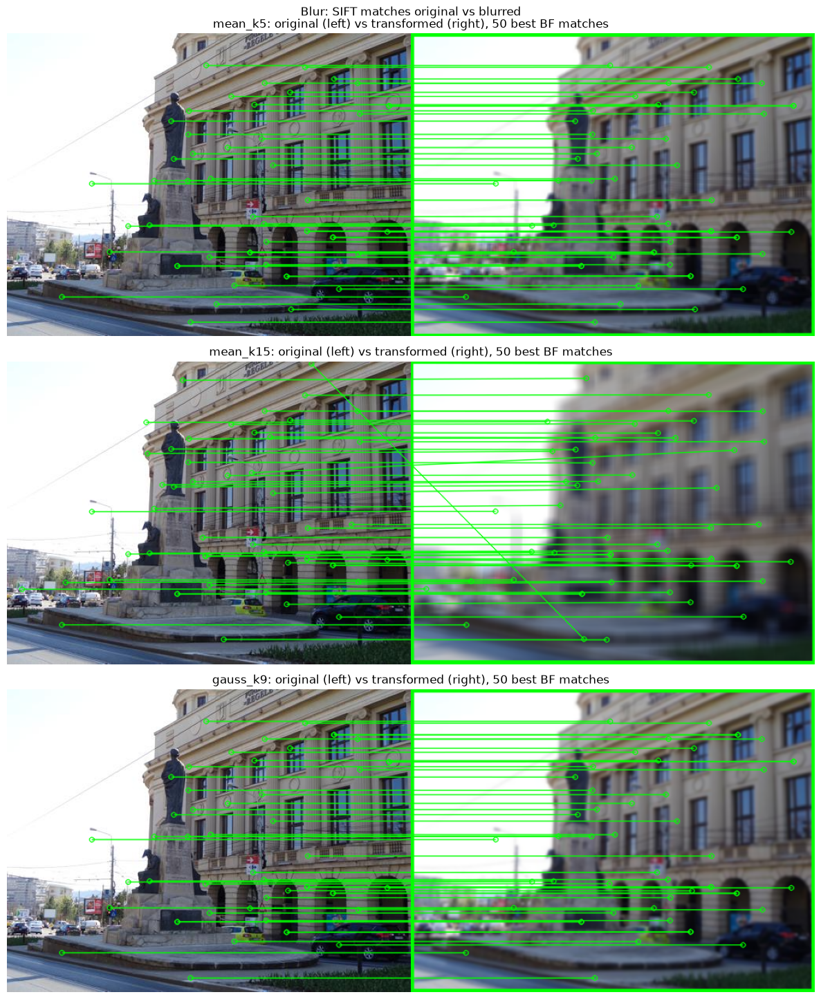

In [11]:
blur_rows, blur_drawn = robustness(img, base, methods, blur_transforms(),
                                   draw_labels={'mean_k5', 'mean_k15', 'gauss_k9'})
show_drawn(blur_drawn, 'Blur: SIFT matches original vs blurred')

In [12]:
show_group_tables(blur_rows, 'mean', 'k=', 'Mean filter (cv2.blur)')
show_group_tables(blur_rows, 'gauss', 'k=', 'Gaussian filter (sigma from the kernel size)')
show_group_tables(blur_rows, 'gauss_sigma', 'sigma ', 'Gaussian 15x15, fixed sigma')

**Mean filter (cv2.blur)** - kp transformed / BF (correct) / kNN (correct)

| method (orig kp) | k=3 | k=5 | k=9 | k=15 |
|---|---|---|---|---|
| Harris (735) | 532 / 422 (421) / 527 (506) | 537 / 345 (330) / 299 (286) | 451 / 238 (210) / 65 (62) | 622 / 184 (122) / 4 (4) |
| FAST (1931) | 767 / 593 (522) / 483 (442) | 238 / 130 (64) / 69 (53) | 19 / 14 (1) / 26 (2) | 0 / 0 (0) / 0 (0) |
| SIFT (1484) | 1164 / 719 (628) / 633 (590) | 534 / 379 (291) / 299 (266) | 228 / 174 (112) / 143 (108) | 102 / 72 (48) / 81 (42) |
| ORB (1000) | 1000 / 744 (727) / 709 (701) | 978 / 570 (543) / 509 (492) | 391 / 238 (195) / 184 (164) | 69 / 51 (29) / 70 (35) |
| BRISK (1608) | 743 / 575 (538) / 585 (555) | 330 / 226 (186) / 251 (218) | 96 / 69 (50) / 79 (59) | 19 / 15 (11) / 34 (14) |
| AKAZE (565) | 487 / 450 (448) / 453 (443) | 391 / 324 (317) / 325 (315) | 220 / 173 (167) / 176 (164) | 73 / 58 (51) / 68 (49) |
| KAZE (758) | 654 / 611 (609) / 619 (607) | 515 / 453 (448) / 476 (449) | 251 / 186 (164) / 197 (164) | 94 / 68 (45) / 66 (43) |

**Mean filter (cv2.blur)** - FLANN (correct) / RANSAC inliers

| method | k=3 | k=5 | k=9 | k=15 |
|---|---|---|---|---|
| Harris | 529 (506) / 506 | 301 (287) / 286 | 75 (68) / 57 | 7 (7) / 0 |
| FAST | - / 442 | - / 53 | - / 14 | - / 0 |
| SIFT | 642 (593) / 590 | 303 (266) / 266 | 144 (108) / 108 | 81 (42) / 43 |
| ORB | - / 701 | - / 493 | - / 163 | - / 34 |
| BRISK | - / 555 | - / 218 | - / 60 | - / 15 |
| AKAZE | - / 443 | - / 315 | - / 164 | - / 48 |
| KAZE | 626 (610) / 607 | 482 (452) / 449 | 199 (164) / 164 | 66 (43) / 41 |

**Gaussian filter (sigma from the kernel size)** - kp transformed / BF (correct) / kNN (correct)

| method (orig kp) | k=3 | k=5 | k=9 | k=15 |
|---|---|---|---|---|
| Harris (735) | 529 / 466 (465) / 553 (547) | 468 / 378 (376) / 481 (461) | 272 / 218 (213) / 272 (258) | 383 / 211 (182) / 136 (122) |
| FAST (1931) | 918 / 772 (723) / 686 (641) | 542 / 437 (386) / 391 (354) | 136 / 92 (49) / 71 (48) | 11 / 8 (0) / 1 (1) |
| SIFT (1484) | 1364 / 833 (735) / 754 (694) | 949 / 609 (514) / 511 (477) | 461 / 325 (247) / 278 (229) | 263 / 200 (134) / 157 (124) |
| ORB (1000) | 1000 / 786 (780) / 758 (752) | 999 / 705 (690) / 682 (672) | 885 / 551 (524) / 502 (489) | 467 / 291 (260) / 256 (242) |
| BRISK (1608) | 901 / 709 (686) / 738 (710) | 606 / 462 (438) / 467 (439) | 285 / 202 (160) / 212 (185) | 109 / 77 (60) / 91 (71) |
| AKAZE (565) | 504 / 473 (472) / 476 (464) | 474 / 426 (421) / 423 (415) | 358 / 297 (285) / 297 (282) | 247 / 189 (181) / 197 (184) |
| KAZE (758) | 685 / 647 (644) / 658 (647) | 618 / 569 (567) / 583 (566) | 442 / 386 (376) / 407 (375) | 269 / 212 (192) / 226 (194) |

... (2 outputs left out)

**Gaussian 15x15, fixed sigma** - kp transformed / BF (correct) / kNN (correct)

| method (orig kp) | sigma 1 | sigma 3 | sigma 5 |
|---|---|---|---|
| Harris (735) | 497 / 404 (402) / 492 (480) | 442 / 205 (160) / 111 (101) | 578 / 185 (108) / 10 (10) |
| FAST (1931) | 574 / 471 (419) / 409 (381) | 4 / 4 (0) / 129 (2) | 0 / 0 (0) / 0 (0) |
| SIFT (1484) | 975 / 627 (522) / 524 (483) | 211 / 157 (107) / 129 (100) | 135 / 99 (60) / 89 (56) |
| ORB (1000) | 1000 / 728 (715) / 699 (689) | 305 / 212 (175) / 193 (167) | 115 / 81 (68) / 92 (70) |
| BRISK (1608) | 629 / 470 (444) / 487 (460) | 82 / 59 (40) / 74 (52) | 32 / 25 (17) / 33 (18) |
| AKAZE (565) | 474 / 427 (421) / 424 (416) | 199 / 154 (149) / 161 (150) | 112 / 90 (77) / 85 (75) |
| KAZE (758) | 620 / 574 (572) / 585 (571) | 225 / 166 (140) / 163 (138) | 128 / 93 (61) / 88 (59) |

**Gaussian 15x15, fixed sigma** - FLANN (correct) / RANSAC inliers

| method | sigma 1 | sigma 3 | sigma 5 |
|---|---|---|---|
| Harris | 498 (481) / 478 | 120 (110) / 90 | 18 (15) / 9 |
| FAST | - / 381 | - / 0 | - / 0 |
| SIFT | 529 (484) / 483 | 132 (100) / 100 | 90 (56) / 56 |
| ORB | - / 689 | - / 168 | - / 69 |
| BRISK | - / 460 | - / 52 | - / 19 |
| AKAZE | - / 416 | - / 149 | - / 75 |
| KAZE | 590 (575) / 571 | 165 (139) / 138 | 90 (59) / 58 |

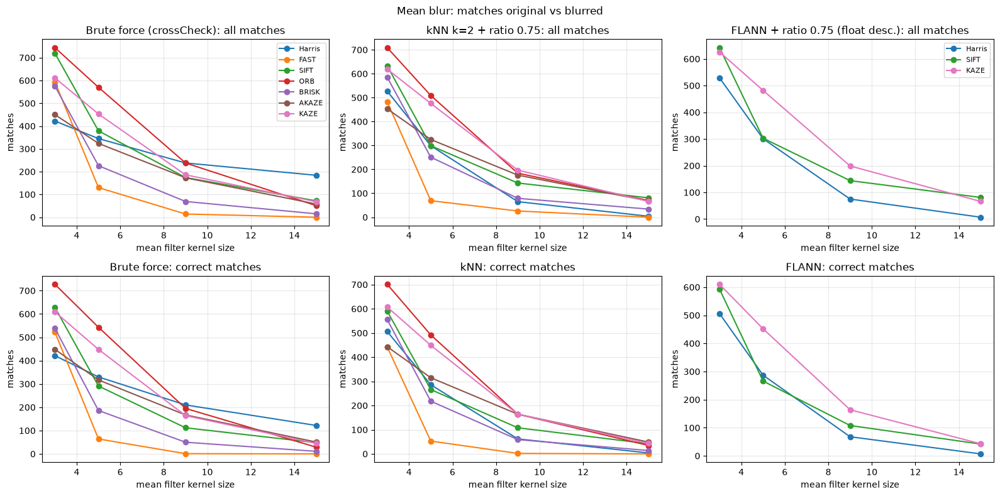

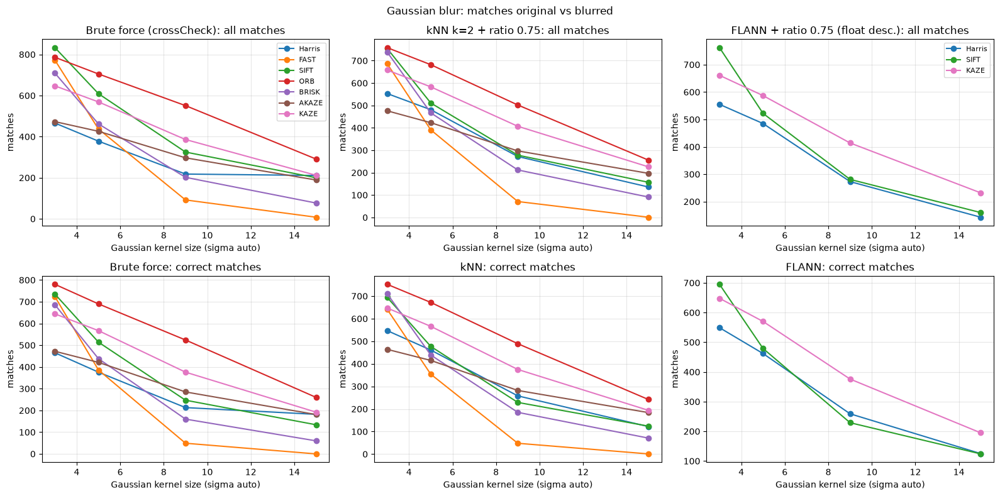

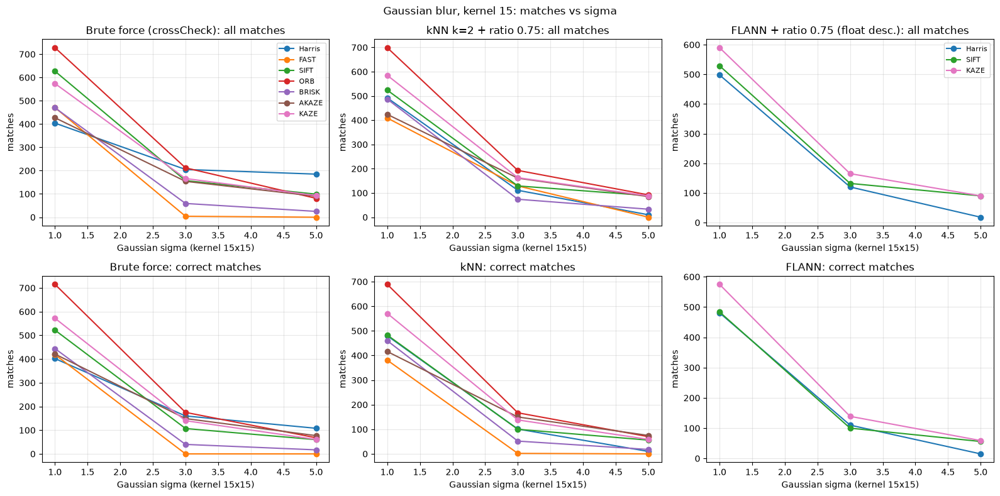

In [13]:
plot_matches(blur_rows, 'mean', 'mean filter kernel size', 'Mean blur: matches original vs blurred')
plot_matches(blur_rows, 'gauss', 'Gaussian kernel size (sigma auto)', 'Gaussian blur: matches original vs blurred')
plot_matches(blur_rows, 'gauss_sigma', 'Gaussian sigma (kernel 15x15)', 'Gaussian blur, kernel 15: matches vs sigma')

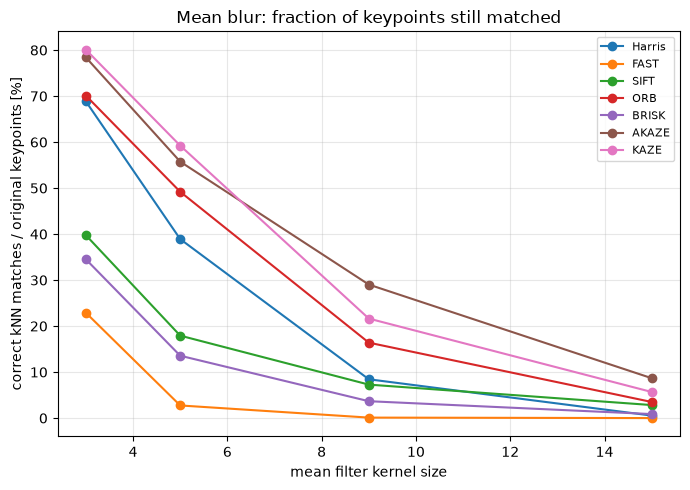

In [14]:
plot_relative(blur_rows, 'mean', 'mean filter kernel size', 'Mean blur: fraction of keypoints still matched')

Every method loses keypoints and matches as the kernel grows; the mean filter hurts more than the Gaussian
of the same size. FAST collapses first (**0 keypoints** for mean k=15 and for sigma 5). ORB is the most stable
on Gaussian blur (524 correct BF matches at k=9); AKAZE / KAZE keep the largest fraction of correct matches
(mean k=5: AKAZE 317/565 = 56 %, KAZE 448/758 = 59 %, SIFT 291/1484 = 20 %). kNN without cross check can
over-count: FAST at sigma 3 has 4 keypoints left but kNN reports 129 "good" matches, only 2 correct.
FLANN gives almost the same counts as exact kNN (SIFT mean k=3: 642 vs 633).

---

### 1d. **Rotation**

Rotation about the centre with `cv2.getRotationMatrix2D` + `cv2.warpAffine` on the same canvas size,
so the image corners are cut off (black triangles). Angles 15, 30, 45, 90, 135, 180 degrees.

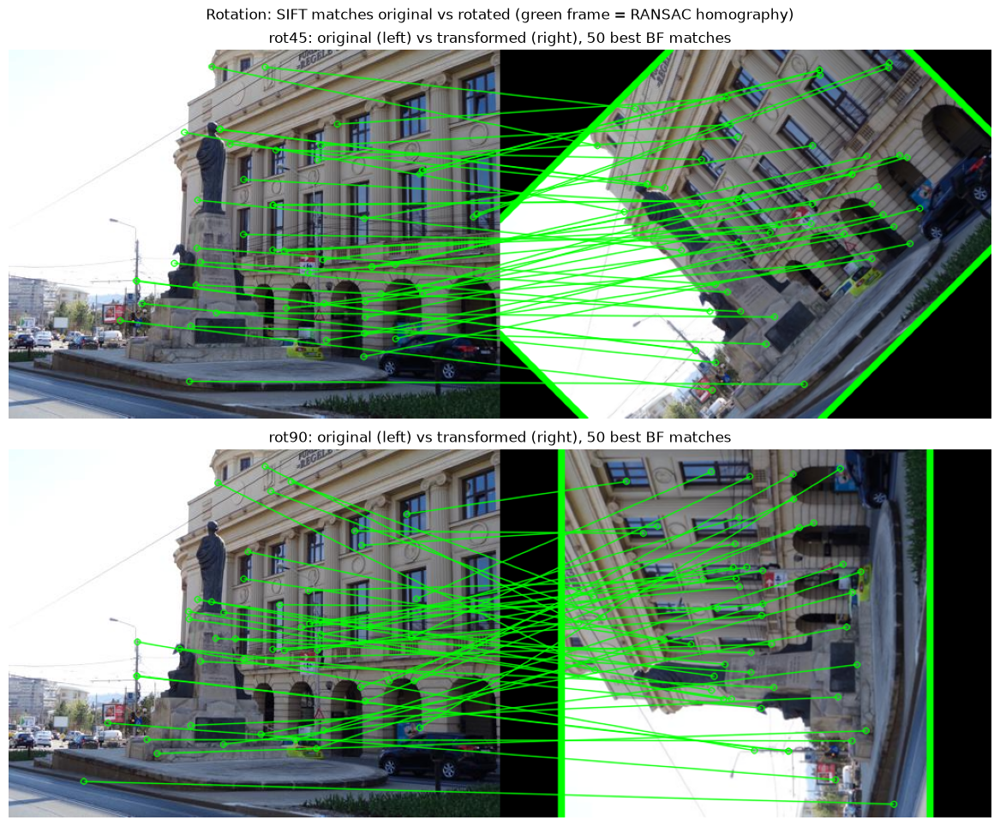

In [15]:
rot_rows, rot_drawn = robustness(img, base, methods, rotation_transforms(img.shape),
                                 draw_labels={'rot45', 'rot90'})
show_drawn(rot_drawn, 'Rotation: SIFT matches original vs rotated (green frame = RANSAC homography)')

In [16]:
show_group_tables(rot_rows, 'rotation', '', 'Rotation [deg]')

**Rotation [deg]** - kp transformed / BF (correct) / kNN (correct)

| method (orig kp) | 15 | 30 | 45 | 90 | 135 | 180 |
|---|---|---|---|---|---|---|
| Harris (735) | 605 / 376 (351) / 45 (41) | 161 / 58 (17) / 2 (0) | 137 / 36 (4) / 0 (0) | 574 / 77 (0) / 0 (0) | 215 / 52 (0) / 1 (0) | 723 / 109 (6) / 1 (0) |
| FAST (1931) | 1590 / 1185 (1113) / 1067 (1021) | 1587 / 1119 (1029) / 1006 (958) | 1263 / 936 (873) / 868 (824) | 1036 / 803 (727) / 722 (678) | 1490 / 1107 (1042) / 1003 (956) | 1931 / 1921 (1920) / 1919 (1918) |
| SIFT (1484) | 1541 / 962 (896) / 943 (884) | 1394 / 892 (822) / 863 (802) | 1350 / 860 (777) / 828 (757) | 1256 / 781 (675) / 716 (652) | 1514 / 931 (859) / 900 (838) | 1464 / 1329 (1322) / 1346 (1324) |
| ORB (1000) | 1000 / 680 (659) / 615 (601) | 1000 / 616 (581) / 536 (524) | 1000 / 582 (547) / 524 (500) | 1000 / 601 (570) / 569 (547) | 1000 / 689 (657) / 643 (620) | 1000 / 1000 (1000) / 1000 (1000) |
| BRISK (1608) | 1361 / 883 (802) / 834 (776) | 1331 / 776 (680) / 720 (669) | 1105 / 710 (615) / 648 (601) | 990 / 651 (564) / 621 (554) | 1396 / 851 (773) / 782 (745) | 1614 / 1443 (1430) / 1447 (1439) |
| AKAZE (565) | 531 / 419 (407) / 416 (400) | 504 / 388 (370) / 368 (352) | 489 / 365 (349) / 363 (339) | 490 / 350 (335) / 349 (331) | 554 / 419 (404) / 411 (396) | 562 / 552 (551) / 549 (548) |
| KAZE (758) | 780 / 554 (532) / 532 (500) | 669 / 469 (457) / 464 (431) | 593 / 437 (424) / 435 (397) | 601 / 457 (442) / 454 (425) | 712 / 506 (489) / 506 (472) | 757 / 666 (660) / 659 (650) |

**Rotation [deg]** - FLANN (correct) / RANSAC inliers

| method | 15 | 30 | 45 | 90 | 135 | 180 |
|---|---|---|---|---|---|---|
| Harris | 59 (55) / 41 | 2 (0) / 0 | 0 (0) / 0 | 0 (0) / 0 | 1 (0) / 0 | 1 (0) / 0 |
| FAST | - / 1021 | - / 958 | - / 824 | - / 678 | - / 956 | - / 1918 |
| SIFT | 947 (885) / 884 | 875 (804) / 802 | 834 (758) / 758 | 722 (655) / 651 | 902 (838) / 839 | 1350 (1324) / 1324 |
| ORB | - / 601 | - / 525 | - / 500 | - / 547 | - / 625 | - / 1000 |
| BRISK | - / 776 | - / 669 | - / 601 | - / 554 | - / 745 | - / 1440 |
| AKAZE | - / 400 | - / 352 | - / 339 | - / 331 | - / 396 | - / 548 |
| KAZE | 533 (501) / 500 | 469 (432) / 431 | 436 (398) / 397 | 458 (426) / 425 | 510 (473) / 472 | 661 (652) / 650 |

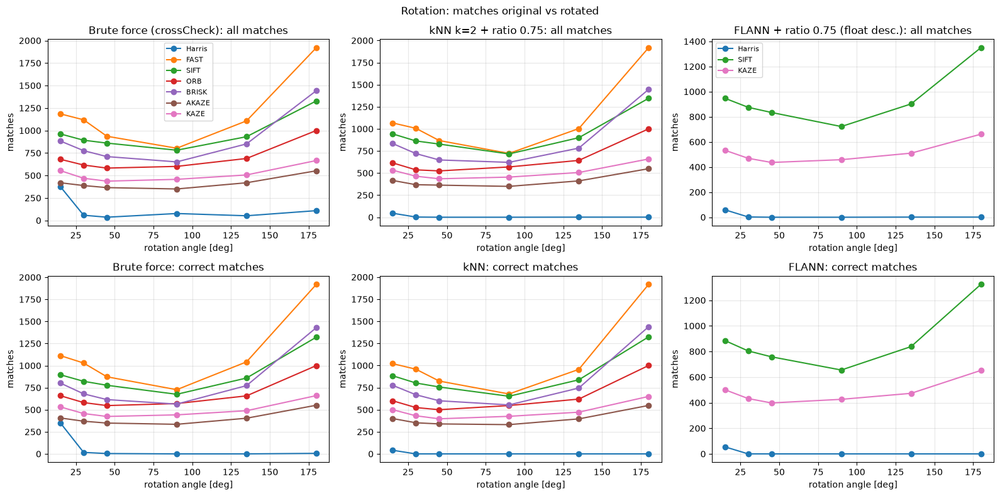

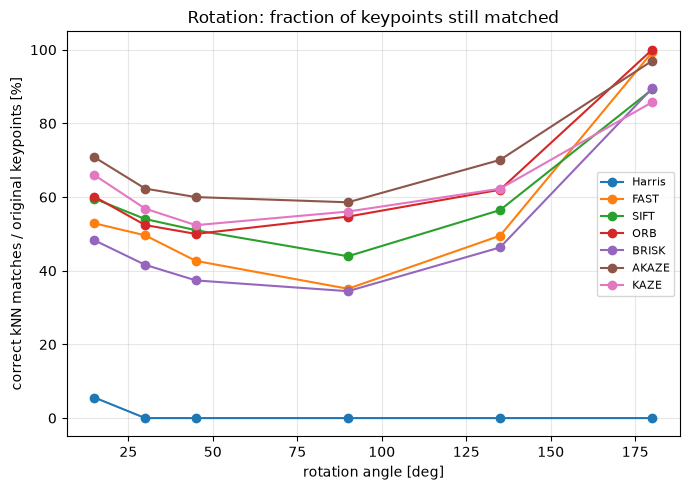

In [17]:
plot_matches(rot_rows, 'rotation', 'rotation angle [deg]', 'Rotation: matches original vs rotated')
plot_relative(rot_rows, 'rotation', 'rotation angle [deg]', 'Rotation: fraction of keypoints still matched')

SIFT, ORB, BRISK, AKAZE, KAZE and FAST+BRISK are **rotation invariant**: correct matches stay roughly constant
for every angle, and at 180 degrees almost everything matches again (ORB 1000/1000, FAST+BRISK 1920/1931,
SIFT 1322/1484). **Harris + upright SIFT descriptor is not**: 351 correct at 15 deg, 17 at 30 deg, about 0
from 45 deg (BF still returns 36-109 matches, all wrong). The dip at 45 / 90 degrees comes from the cut corners
and the interpolation. RANSAC agrees with the ground truth: SIFT rot45 has 757 correct kNN matches and 758 inliers.

---

### 1e. **Gaussian noise**

Zero-mean Gaussian noise (`np.random.default_rng(0).normal(0, sigma)`) added to the float image, clipped
to 0..255, sigma = 5, 10, 20, 30, 50.

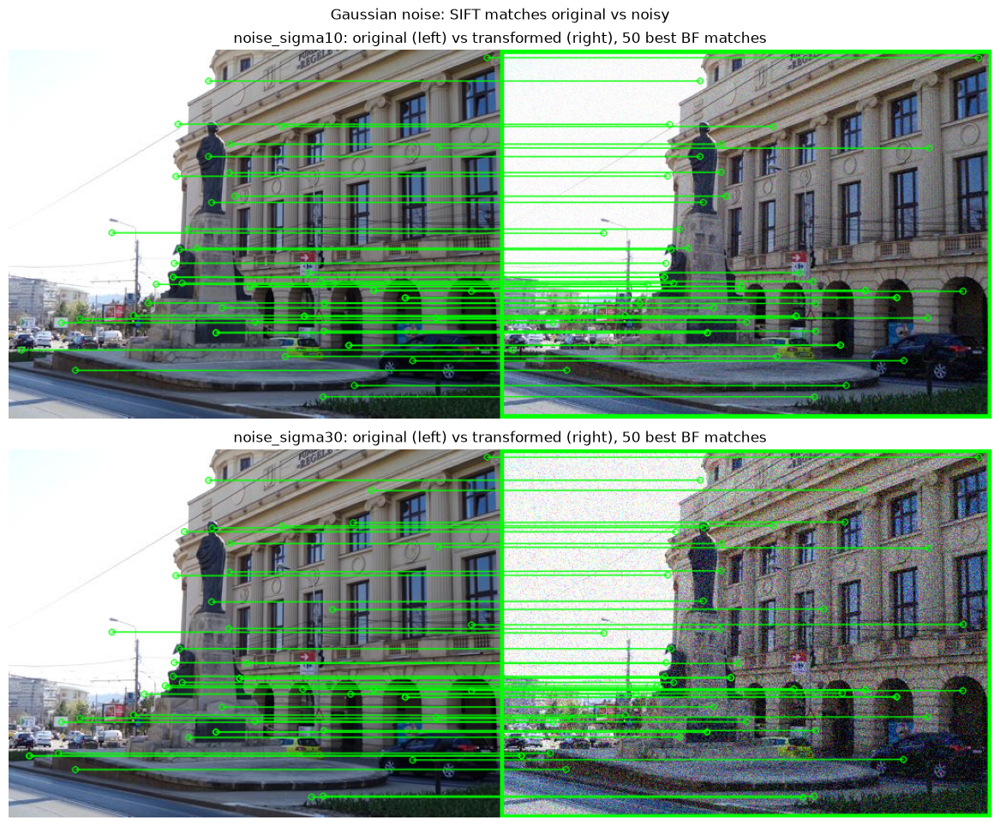

In [18]:
noise_rows, noise_drawn = robustness(img, base, methods, noise_transforms(),
                                     draw_labels={'noise_sigma10', 'noise_sigma30'})
show_drawn(noise_drawn, 'Gaussian noise: SIFT matches original vs noisy')

In [19]:
show_group_tables(noise_rows, 'noise', 'sigma ', 'Gaussian noise')

**Gaussian noise** - kp transformed / BF (correct) / kNN (correct)

| method (orig kp) | sigma 5 | sigma 10 | sigma 20 | sigma 30 | sigma 50 |
|---|---|---|---|---|---|
| Harris (735) | 714 / 668 (667) / 694 (691) | 705 / 619 (618) / 658 (655) | 927 / 593 (585) / 609 (604) | 1858 / 587 (580) / 491 (487) | 5873 / 598 (587) / 209 (209) |
| FAST (1931) | 2099 / 1603 (1571) / 1543 (1514) | 2965 / 1495 (1384) / 1253 (1222) | 7005 / 1410 (1126) / 800 (776) | 10424 / 1271 (889) / 460 (444) | 13945 / 1159 (537) / 163 (156) |
| SIFT (1484) | 1576 / 1139 (1073) / 1100 (1057) | 1716 / 986 (872) / 885 (829) | 1728 / 769 (600) / 592 (527) | 1654 / 673 (455) / 444 (382) | 1566 / 543 (287) / 258 (208) |
| ORB (1000) | 1000 / 907 (905) / 919 (917) | 1000 / 858 (853) / 850 (846) | 1000 / 784 (769) / 733 (724) | 1000 / 702 (680) / 642 (628) | 1000 / 576 (544) / 471 (452) |
| BRISK (1608) | 1683 / 1366 (1349) / 1349 (1334) | 1908 / 1251 (1210) / 1178 (1150) | 3515 / 1138 (1027) / 915 (882) | 6491 / 1082 (857) / 681 (647) | 11588 / 1032 (615) / 391 (369) |
| AKAZE (565) | 581 / 533 (531) / 527 (526) | 587 / 513 (508) / 506 (502) | 618 / 488 (480) / 471 (467) | 662 / 454 (436) / 434 (426) | 779 / 422 (362) / 363 (343) |
| KAZE (758) | 790 / 718 (716) / 718 (712) | 795 / 695 (690) / 694 (687) | 785 / 641 (630) / 635 (623) | 797 / 601 (582) / 599 (580) | 882 / 545 (512) / 515 (489) |

**Gaussian noise** - FLANN (correct) / RANSAC inliers

| method | sigma 5 | sigma 10 | sigma 20 | sigma 30 | sigma 50 |
|---|---|---|---|---|---|
| Harris | 695 (691) / 691 | 659 (655) / 655 | 609 (604) / 604 | 493 (487) / 487 | 212 (212) / 209 |
| FAST | - / 1514 | - / 1222 | - / 776 | - / 444 | - / 156 |
| SIFT | 1100 (1058) / 1057 | 888 (829) / 829 | 597 (530) / 527 | 449 (385) / 382 | 259 (206) / 208 |
| ORB | - / 917 | - / 846 | - / 724 | - / 628 | - / 452 |
| BRISK | - / 1334 | - / 1150 | - / 882 | - / 647 | - / 369 |
| AKAZE | - / 526 | - / 502 | - / 467 | - / 426 | - / 343 |
| KAZE | 720 (712) / 712 | 697 (690) / 687 | 640 (626) / 623 | 601 (580) / 580 | 519 (491) / 489 |

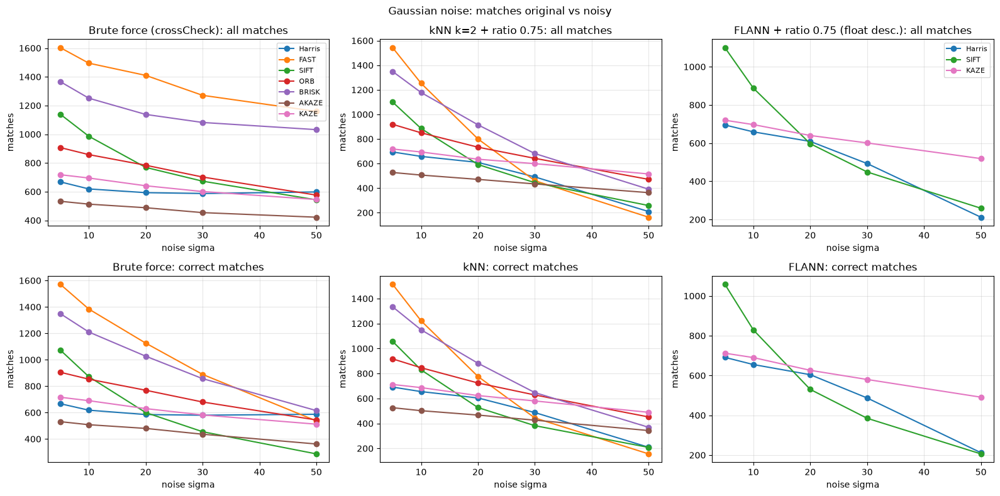

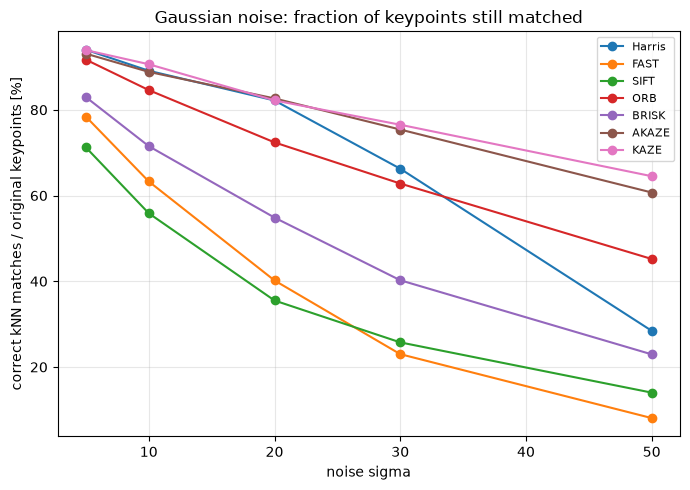

In [20]:
plot_matches(noise_rows, 'noise', 'noise sigma', 'Gaussian noise: matches original vs noisy')
plot_relative(noise_rows, 'noise', 'noise sigma', 'Gaussian noise: fraction of keypoints still matched')

Noise is the opposite of blur: FAST, BRISK and Harris find more and more (fake) keypoints
(FAST 1931 -> 13945 at sigma 50, Harris 735 -> 5873) while the correct matches drop (FAST 1571 -> 537 BF correct).
SIFT, KAZE, AKAZE and ORB keep a stable keypoint count. Most robust in relative terms: KAZE (489/758 = 65 % correct
kNN at sigma 50), AKAZE (343/565 = 61 %), ORB (452/1000 = 45 %); SIFT keeps only 14 % (208/1484).

---

### Extra: **RANSAC homography inliers** (blur, rotation, noise)

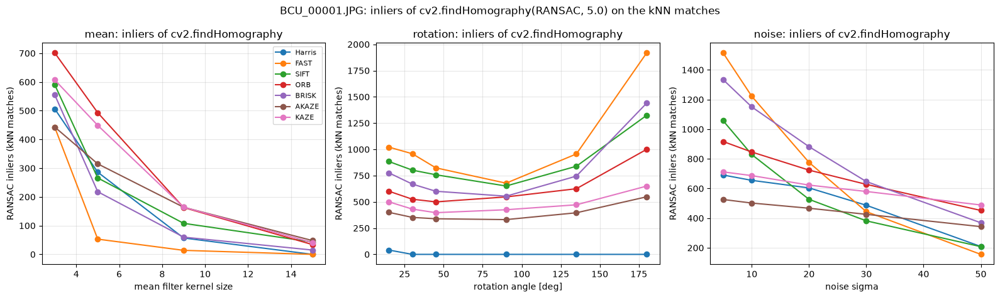

In [21]:
plot_inliers(blur_rows, rot_rows, noise_rows, 'BCU_00001.JPG: inliers of cv2.findHomography(RANSAC, 5.0) on the kNN matches')

The inliers need no ground truth and agree with the "correct" column almost exactly (SIFT rot45: 757 correct vs
758 inliers; ORB rot180: 1000 vs 1000). Harris at mean k=15 has 4 correct matches but 0 inliers: fewer than
10 matches, so no homography is computed.

---

### Part 1 again on `images/lena.tif` (short second pass)

Part 1 takes only a few seconds per image, so the same analysis is repeated on lena (512x512).
Only the keypoints, the counts and the fraction of correct kNN matches are shown.

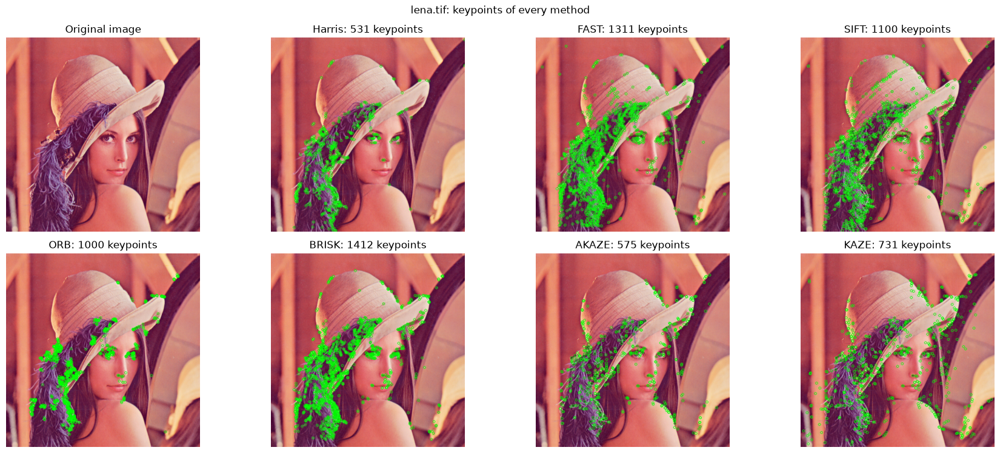

| method | keypoints | desc length | desc dtype | norm | empty cells (of 64) | max cell | max cell share | mean kp size | detect ms |
|---|---|---|---|---|---|---|---|---|---|
| Harris | 531 | 128 | float32 | L2 | 31 | 74 | 0.139 | 7.0 | 5.2 |
| FAST | 1311 | 64 | uint8 | HAMMING | 16 | 132 | 0.101 | 7.0 | 6.8 |
| SIFT | 1100 | 128 | float32 | L2 | 11 | 100 | 0.091 | 4.37 | 12.8 |
| ORB | 1000 | 32 | uint8 | HAMMING | 35 | 149 | 0.149 | 53.83 | 3.2 |
| BRISK | 1412 | 64 | uint8 | HAMMING | 20 | 160 | 0.113 | 21.16 | 12.9 |
| AKAZE | 575 | 61 | uint8 | HAMMING | 25 | 50 | 0.087 | 7.92 | 8.2 |
| KAZE | 731 | 64 | float32 | L2 | 12 | 48 | 0.066 | 10.75 | 28.6 |

In [22]:
lena = cv2.imread('images/lena.tif', cv2.IMREAD_COLOR)
lena_base = detect_all(to_gray(lena), methods)
show_keypoints(lena, lena_base, 'lena.tif: keypoints of every method')
lena_counts, lena_grids = count_rows(lena, lena_base)
show_table(COUNT_HEADER, lena_counts)

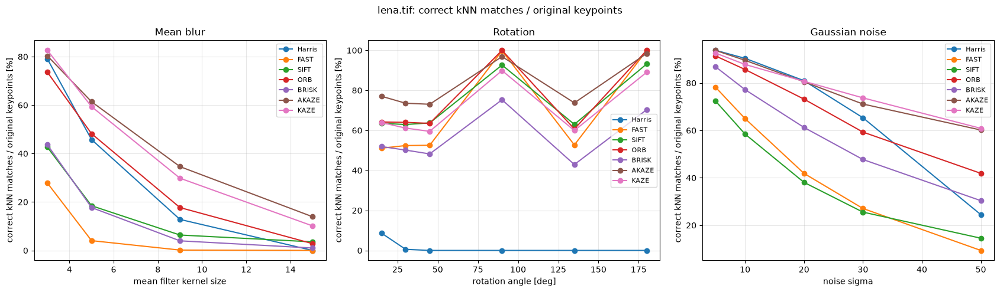

In [23]:
lena_blur, _ = robustness(lena, lena_base, methods, blur_transforms(), draw_labels=set())
lena_rot, _ = robustness(lena, lena_base, methods, rotation_transforms(lena.shape), draw_labels=set())
lena_noise, _ = robustness(lena, lena_base, methods, noise_transforms(), draw_labels=set())

fig, axs = plt.subplots(1, 3, figsize=(17, 5))
plot_relative(lena_blur, 'mean', 'mean filter kernel size', 'Mean blur', ax=axs[0])
plot_relative(lena_rot, 'rotation', 'rotation angle [deg]', 'Rotation', ax=axs[1])
plot_relative(lena_noise, 'noise', 'noise sigma', 'Gaussian noise', ax=axs[2])
fig.suptitle('lena.tif: correct kNN matches / original keypoints')
plt.tight_layout()
plt.show()

lena.tif: Harris 531, FAST 1311, SIFT 1100, ORB 1000, BRISK 1412, AKAZE 575, KAZE 731 keypoints. They concentrate on
the hat feathers, the eyes / mouth and the hat band; the smooth skin and the wall stay empty (Harris 31 empty cells,
ORB 35). The curves tell the same story as on the main image: FAST has 0 keypoints at mean k=15, Harris + upright
SIFT has about 0 correct matches from 30 degrees, and at sigma 50 KAZE (61 %) and AKAZE (60 %) keep the most correct
kNN matches while SIFT keeps 15 %. On the square 512x512 canvas the 90 and 180 degree rotations cut nothing off,
so almost every keypoint is matched again.

---

### Part 2. **Location classification (BCU / BVD_COPOU / UAIC)**

Train 400 images (BCU 70, BVD_COPOU 130, UAIC 200), test 83 images (15 / 27 / 41), all 516x387.
Methods: SIFT (`nfeatures=500`), ORB (`nfeatures=500`), AKAZE, BRISK (only the 1000 strongest keypoints kept),
KAZE. SURF is not available. Matchers: brute force with cross check (count of matches) and kNN k=2 + ratio 0.75
(count of good matches).

In [24]:
CLASSES = ['BCU', 'BVD_COPOU', 'UAIC']
MATCHERS = ['bf_crosscheck', 'knn_ratio']


# list of (path, label, gray image) for data/<split>/<label>/*
def load_split(split):
    items = []
    for label in CLASSES:
        for f in sorted(glob.glob(os.path.join('data', split, label, '*'))):
            gray = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
            if gray is None:
                print(f'cannot read {f}, skipped')
                continue
            items.append((f, label, gray))
    return items


# normal detector first, then relaxed versions, until >= 1 keypoint; None if nothing worked
def detect_with_retry(gray, variants, name, path):
    for i, (factory, norm, max_kp) in enumerate(variants):
        kps, desc = factory().detectAndCompute(gray, None)
        if kps is not None and len(kps) > 0 and desc is not None:
            kps, desc = keep_strongest(list(kps), desc, max_kp)
            if i > 0:
                print(f'{name}: {os.path.basename(path)} needed relaxed parameters (variant {i})')
            return kps, desc, norm, i
    print(f'{name}: NO keypoints for {os.path.basename(path)} even with relaxed parameters')
    return None


# -> list of dict(path, label, kps, desc, norm, relaxed); images without keypoints get desc None
def describe_split(items, variants, name):
    out = []
    for path, label, gray in items:
        res = detect_with_retry(gray, variants, name, path)
        if res is None:
            out.append(dict(path=path, label=label, kps=[], desc=None, norm=variants[0][1], relaxed=-1))
        else:
            kps, desc, norm, variant = res
            out.append(dict(path=path, label=label, kps=kps, desc=desc, norm=norm, relaxed=variant))
    return out


# number of matches between one test image and every train image, for both matchers
def match_scores(test_desc, train_items, norm):
    bf = cv2.BFMatcher(norm, crossCheck=True)
    knn = cv2.BFMatcher(norm)
    n = len(train_items)
    scores = {m: np.zeros(n, dtype=int) for m in MATCHERS}
    for j, tr in enumerate(train_items):
        d2 = tr['desc']
        if d2 is None:
            scores['bf_crosscheck'][j] = -1   # train image without keypoints: never wins
            scores['knn_ratio'][j] = -1
            continue
        scores['bf_crosscheck'][j] = len(bf.match(test_desc, d2))
        if len(d2) >= 2:
            pairs = knn.knnMatch(test_desc, d2, k=2)
            scores['knn_ratio'][j] = sum(1 for p in pairs
                                         if len(p) == 2 and p[0].distance < RATIO * p[1].distance)
        else:
            scores['knn_ratio'][j] = 0
    return scores


# one best image -> its label; several -> majority vote; tie -> 'parity case' + random (seeded) label
def vote(best_labels, test_name, rng, parity_log, where=''):
    if len(best_labels) == 1:
        return best_labels[0], False
    counts = Counter(best_labels)
    top = max(counts.values())
    winners = sorted(l for l, c in counts.items() if c == top)
    if len(winners) == 1:
        return winners[0], False
    print(f'parity case: {test_name} [{where}] tied labels: {", ".join(winners)}')
    parity_log.append((test_name, winners))
    return rng.choice(winners), True


# both matchers for one method -> {matcher: summary dict with accuracy and confusion matrix}
def classify(test_items, train_items, name):
    rng = {m: random.Random(0) for m in MATCHERS}
    preds = {m: [] for m in MATCHERS}
    parity = {m: [] for m in MATCHERS}
    no_kp = 0
    t0 = time.time()
    for te in test_items:
        test_name = os.path.basename(te['path'])
        if te['desc'] is None:
            no_kp += 1
            print(f'{name}: {test_name} has no keypoints -> random label')
            for m in MATCHERS:
                label = rng[m].choice(CLASSES)
                preds[m].append((te['label'], label))
            continue
        scores = match_scores(te['desc'], train_items, te['norm'])
        for m in MATCHERS:
            s = scores[m]
            best = int(s.max())
            idx = np.nonzero(s == best)[0]
            best_labels = [train_items[j]['label'] for j in idx]
            label, was_parity = vote(best_labels, test_name, rng[m], parity[m], f'{name} {m}')
            preds[m].append((te['label'], label))
    elapsed = time.time() - t0

    summaries = {}
    for m in MATCHERS:
        cm = np.zeros((3, 3), dtype=int)
        for true, pred in preds[m]:
            cm[CLASSES.index(true), CLASSES.index(pred)] += 1
        correct = int(np.trace(cm))
        summaries[m] = dict(method=name, matcher=m, accuracy=correct / len(preds[m]), correct=correct,
                            n_test=len(preds[m]), parity_cases=len(parity[m]),
                            parity_images=[p[0] for p in parity[m]],
                            test_without_keypoints=no_kp, cm=cm, seconds=elapsed)
    return summaries


def plot_confusions(summaries):
    names = list(dict.fromkeys(s['method'] for s in summaries))
    fig, axs = plt.subplots(2, len(names), figsize=(4.4 * len(names), 9))
    for s in summaries:
        ax = axs[MATCHERS.index(s['matcher']), names.index(s['method'])]
        cm = s['cm']
        ax.imshow(cm, cmap='Blues')
        for r in range(3):
            for c in range(3):
                ax.text(c, r, str(cm[r, c]), ha='center', va='center',
                        color='white' if cm[r, c] > cm.max() / 2 else 'black', fontsize=12)
        ax.set_xticks(range(3))
        ax.set_yticks(range(3))
        ax.set_xticklabels(CLASSES, rotation=20)
        ax.set_yticklabels(CLASSES)
        ax.set_xlabel('predicted')
        ax.set_ylabel('true')
        ax.set_title(f"{s['method']} + {s['matcher']}: accuracy {s['accuracy']:.3f}")
    fig.suptitle('Part 2: confusion matrices (rows = true class, columns = predicted class)')
    plt.tight_layout()
    plt.show()


def plot_accuracies(summaries):
    names = list(dict.fromkeys(s['method'] for s in summaries))
    x = np.arange(len(names))
    width = 0.38
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for k, m in enumerate(MATCHERS):
        accs = [next(s['accuracy'] for s in summaries if s['method'] == meth and s['matcher'] == m)
                for meth in names]
        bars = ax.bar(x + (k - 0.5) * width, [100 * a for a in accs], width, label=m)
        for b, a in zip(bars, accs):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f'{100 * a:.1f}',
                    ha='center', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(names)
    ax.set_ylabel('accuracy [%]')
    ax.set_ylim(0, 105)
    ax.set_title('Part 2: classification accuracy per method and matcher')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()


# matches between the first test image of each class and its best train image (brute force)
def example_matches(test_items, train_items, n_per_class=1):
    done = Counter()
    out = []
    for te in test_items:
        if done[te['label']] >= n_per_class or te['desc'] is None:
            continue
        done[te['label']] += 1
        bf = cv2.BFMatcher(te['norm'], crossCheck=True)
        best_j, best_n = -1, -1
        for j, tr in enumerate(train_items):
            if tr['desc'] is None:
                continue
            n = len(bf.match(te['desc'], tr['desc']))
            if n > best_n:
                best_j, best_n = j, n
        tr = train_items[best_j]
        img1 = cv2.imread(te['path'])
        img2 = cv2.imread(tr['path'])
        matches = bf_matches(te['desc'], tr['desc'], te['norm'])[:50]
        drawn = cv2.drawMatches(img1, te['kps'], img2, tr['kps'], matches, None,
                                matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        title = (f"test {os.path.basename(te['path'])} ({te['label']}) vs best train "
                 f"{os.path.basename(tr['path'])} ({tr['label']}): {best_n} BF matches, 50 best drawn")
        out.append((title, drawn))
    return out

In [25]:
train = load_split('train')
test = load_split('test')
print(f'train images: {len(train)} {dict(Counter(l for _, l, _ in train))}')
print(f'test images:  {len(test)} {dict(Counter(l for _, l, _ in test))}')

train images: 400 {'BCU': 70, 'BVD_COPOU': 130, 'UAIC': 200}
test images:  83 {'BCU': 15, 'BVD_COPOU': 27, 'UAIC': 41}


### 2a. **Keypoints and descriptors for every image**

When a detector gives 0 keypoints for an image we retry with relaxed parameters
(SIFT contrastThreshold 0.04 -> 0.01 -> 0.001, ORB fastThreshold 20 -> 5 -> 1, AKAZE / KAZE threshold
1e-3 -> 1e-4 -> 1e-5, BRISK thresh 30 -> 10 -> 1).

In [26]:
described = {}
kp_stats = []
for name, variants in part2_method_variants().items():
    t = time.time()
    train_items = describe_split(train, variants, name)
    test_items = describe_split(test, variants, name)
    n_train_dropped = sum(1 for it in train_items if it['desc'] is None)
    n_test_nokp = sum(1 for it in test_items if it['desc'] is None)
    n_relaxed = sum(1 for it in train_items + test_items if it['relaxed'] > 0)
    kp_train = [len(it['kps']) for it in train_items if it['desc'] is not None]
    kp_stats.append([name, round(float(np.mean(kp_train)), 1), min(kp_train), max(kp_train),
                     n_relaxed, n_train_dropped, n_test_nokp, round(time.time() - t, 1)])
    described[name] = (train_items, test_items)

show_table(['method', 'mean kp / train img', 'min', 'max', 'images needing relaxed params',
            'train dropped', 'test without kp', 'detect s'], kp_stats)

| method | mean kp / train img | min | max | images needing relaxed params | train dropped | test without kp | detect s |
|---|---|---|---|---|---|---|---|
| SIFT | 498.3 | 110 | 502 | 0 | 0 | 0 | 5.3 |
| ORB | 497.7 | 180 | 500 | 0 | 0 | 0 | 1.5 |
| AKAZE | 691.1 | 42 | 1721 | 0 | 0 | 0 | 3.6 |
| BRISK | 947.5 | 48 | 1000 | 0 | 0 | 0 | 10.2 |
| KAZE | 966.2 | 98 | 2391 | 0 | 0 | 0 | 11.0 |

Every image got keypoints with the default parameters, so the retry was implemented but never needed and no
image was dropped or labelled at random. Mean keypoints per train image: SIFT 498, ORB 498, AKAZE 691,
BRISK 948, KAZE 966.

---

### 2b. **Classify the test images**

For every test image count the matches with each of the 400 train images; take the train images with the
maximum count; one image -> its folder label, several -> majority vote; a tie prints `parity case: <image>`
and picks a random label among the tied ones (`random.Random(0)`, reproducible). This takes a few minutes.

In [27]:
all_summaries = []
for name, (train_items, test_items) in described.items():
    usable_train = [it for it in train_items if it['desc'] is not None]
    summaries = classify(test_items, usable_train, name)
    for m in MATCHERS:
        s = summaries[m]
        s['train_dropped'] = sum(1 for it in train_items if it['desc'] is None)
        all_summaries.append(s)
        print(f"==> {name:6s} {m:13s} accuracy {s['accuracy']:.3f} ({s['correct']}/{s['n_test']}), "
              f"parity cases {s['parity_cases']}, matching {s['seconds']:.0f} s")

parity case: BCU_00083.JPG [SIFT knn_ratio] tied labels: BCU, UAIC


parity case: BC_00134.JPG [SIFT bf_crosscheck] tied labels: BCU, UAIC


parity case: BC_00137.JPG [SIFT bf_crosscheck] tied labels: BVD_COPOU, UAIC


parity case: BC_00139.JPG [SIFT knn_ratio] tied labels: BVD_COPOU, UAIC


parity case: BC_00149.JPG [SIFT bf_crosscheck] tied labels: BVD_COPOU, UAIC


parity case: BC_00150.JPG [SIFT bf_crosscheck] tied labels: BVD_COPOU, UAIC


... (48 outputs left out)

parity case: UAIC_00217.JPG [KAZE knn_ratio] tied labels: BVD_COPOU, UAIC


parity case: UAIC_00219.JPG [KAZE knn_ratio] tied labels: BCU, BVD_COPOU


parity case: UAIC_00220.JPG [KAZE knn_ratio] tied labels: BVD_COPOU, UAIC


==> KAZE   bf_crosscheck accuracy 0.602 (50/83), parity cases 4, matching 68 s
==> KAZE   knn_ratio     accuracy 0.675 (56/83), parity cases 5, matching 68 s


---

### 2c. **Accuracy and confusion matrices**

In [28]:
rows = []
for s in all_summaries:
    cm = s['cm']
    recalls = [f'{cm[i, i]}/{cm[i].sum()}' for i in range(3)]
    rows.append([s['method'], s['matcher'], f"{100 * s['accuracy']:.1f} %", f"{s['correct']}/{s['n_test']}",
                 s['parity_cases']] + recalls + [' ; '.join(' '.join(map(str, r)) for r in cm)])
show_table(['method', 'matcher', 'accuracy', 'correct', 'parity cases', 'recall BCU', 'recall BVD_COPOU',
            'recall UAIC', 'confusion matrix (rows true, cols predicted)'], rows)

| method | matcher | accuracy | correct | parity cases | recall BCU | recall BVD_COPOU | recall UAIC | confusion matrix (rows true, cols predicted) |
|---|---|---|---|---|---|---|---|---|
| SIFT | bf_crosscheck | 57.8 % | 48/83 | 8 | 7/15 | 11/27 | 30/41 | 7 4 4 ; 1 11 15 ; 0 11 30 |
| SIFT | knn_ratio | 67.5 % | 56/83 | 5 | 11/15 | 15/27 | 30/41 | 11 2 2 ; 1 15 11 ; 6 5 30 |
| ORB | bf_crosscheck | 56.6 % | 47/83 | 5 | 9/15 | 17/27 | 21/41 | 9 3 3 ; 1 17 9 ; 2 18 21 |
| ORB | knn_ratio | 42.2 % | 35/83 | 17 | 7/15 | 9/27 | 19/41 | 7 3 5 ; 1 9 17 ; 9 13 19 |
| AKAZE | bf_crosscheck | 44.6 % | 37/83 | 1 | 1/15 | 5/27 | 31/41 | 1 2 12 ; 0 5 22 ; 0 10 31 |
| AKAZE | knn_ratio | 63.9 % | 53/83 | 4 | 12/15 | 8/27 | 33/41 | 12 0 3 ; 7 8 12 ; 6 2 33 |
| BRISK | bf_crosscheck | 44.6 % | 37/83 | 2 | 5/15 | 13/27 | 19/41 | 5 1 9 ; 0 13 14 ; 1 21 19 |
| BRISK | knn_ratio | 49.4 % | 41/83 | 6 | 13/15 | 5/27 | 23/41 | 13 0 2 ; 6 5 16 ; 13 5 23 |
| KAZE | bf_crosscheck | 60.2 % | 50/83 | 4 | 3/15 | 8/27 | 39/41 | 3 6 6 ; 0 8 19 ; 0 2 39 |
| KAZE | knn_ratio | 67.5 % | 56/83 | 5 | 8/15 | 13/27 | 35/41 | 8 3 4 ; 5 13 9 ; 3 3 35 |

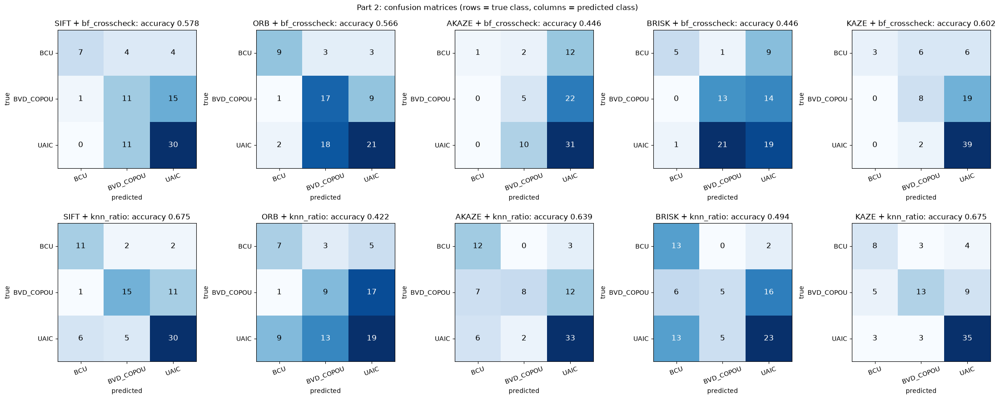

In [29]:
plot_confusions(all_summaries)

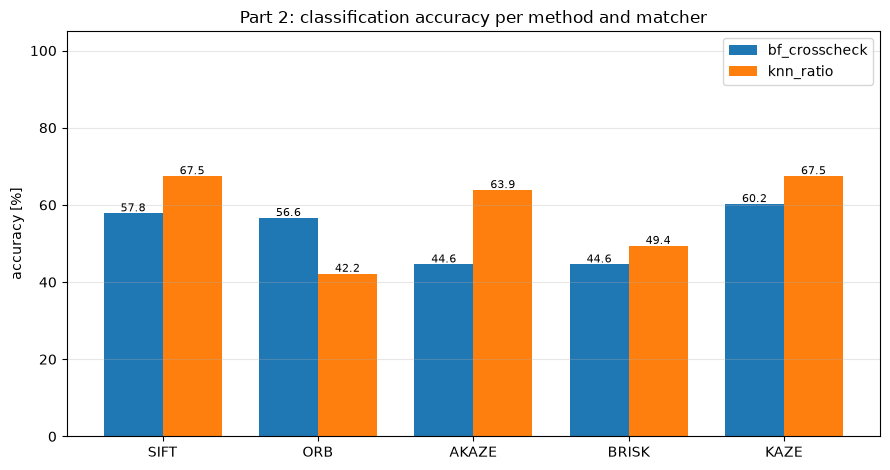

In [30]:
plot_accuracies(all_summaries)

Best: **SIFT + kNN and KAZE + kNN 67.5 %** (56/83); AKAZE + kNN 63.9 %, BRISK + kNN 49.4 %, worst ORB + kNN 42.2 %
(17 parity cases, its good-match counts are tiny so ties are frequent). kNN + ratio beats BF cross check for
SIFT, AKAZE, BRISK and KAZE: the raw BF count rewards train images with many keypoints, so BF is biased toward
the big UAIC class (AKAZE BF: 31 of 41 UAIC right but 1 of 15 BCU). Random guessing gives 33 %, always "UAIC" 49 %.

---

### 2d. **Example matches (SIFT, first test image of each class vs its best train image)**

test BCU_00071.JPG (BCU) vs best train BCU_00070.JPG (BCU): 263 BF matches, 50 best drawn
test BC_00131.JPG (BVD_COPOU) vs best train BC_00130.JPG (BVD_COPOU): 235 BF matches, 50 best drawn
test UAIC_00201.JPG (UAIC) vs best train UAIC_00200.JPG (UAIC): 341 BF matches, 50 best drawn


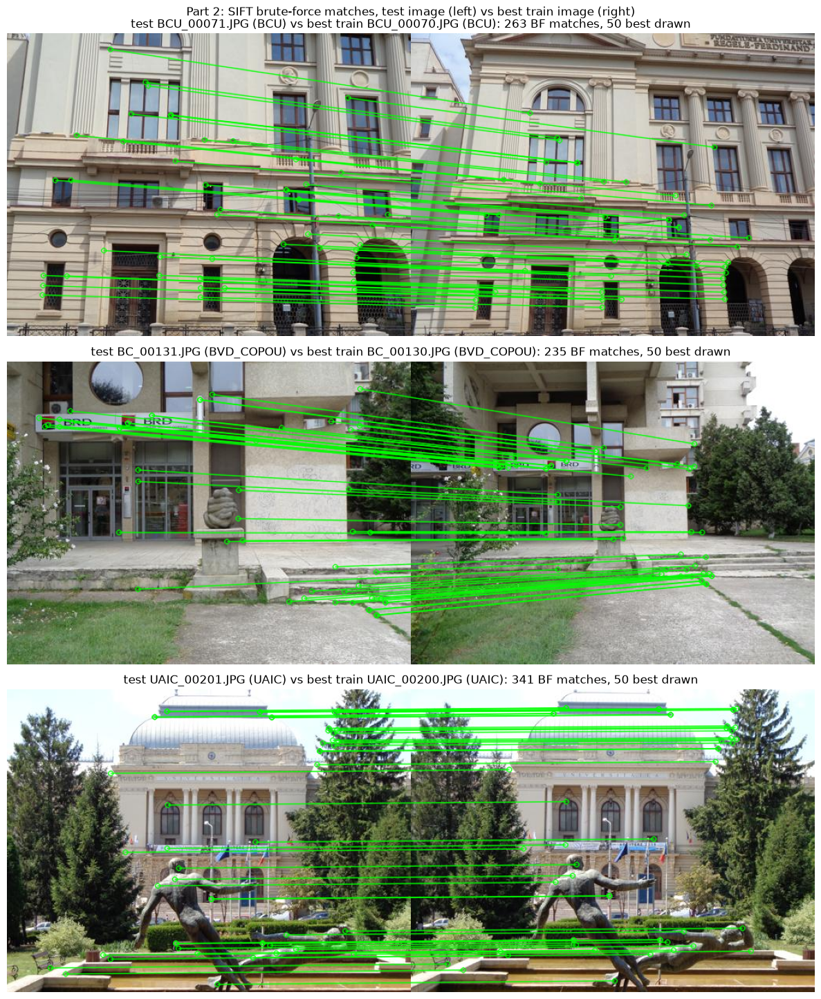

In [31]:
train_items, test_items = described['SIFT']
examples = example_matches(test_items, [it for it in train_items if it['desc'] is not None])
fig, axs = plt.subplots(len(examples), 1, figsize=(13, 4.9 * len(examples)))
for ax, (title, drawn) in zip(axs, examples):
    print(title)
    ax.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
fig.suptitle('Part 2: SIFT brute-force matches, test image (left) vs best train image (right)')
plt.tight_layout()
plt.show()

The first test image of each class is a near-duplicate of the last train image of that class (BCU_00071 vs
BCU_00070: 263 BF matches, BC_00131 vs BC_00130: 235, UAIC_00201 vs UAIC_00200: 341), so the 50 best matches lie on
the same building and these images are always classified right. Later test images are taken from other viewpoints
or show trees, cars and sky; they share only a few distinctive matches with any train image, and that is where the
errors come from.

---

### Conclusions

- Corner detectors (Harris, FAST, BRISK, ORB) cluster on textures and corners; SIFT, KAZE and AKAZE spread more evenly; nobody finds points in the sky.
- Blur kills FAST first (0 keypoints at mean 15x15); ORB, AKAZE and KAZE resist best. Noise creates fake corners for FAST, BRISK and Harris, while KAZE, AKAZE and ORB keep more than half of their correct matches even at sigma 50.
- Every method with an orientation is rotation invariant; Harris with an upright SIFT descriptor is not.
- kNN + ratio test gives fewer but cleaner matches than brute force; the RANSAC homography inliers agree with the ground-truth "correct" count.
- Place classification by the most similar train image: best 67.5 % (SIFT / KAZE + kNN), worst 42.2 % (ORB + kNN). SURF could not be tested (not in this OpenCV build).